In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)


Датасет Titanic. Целевая переменная - 'Survived' (0/1).  

In [2]:
df = pd.read_csv('Titanic-Dataset.csv')

print('Shape:', df.shape)

print(f'nulls:{df.isna().sum()}')
print(f'duplicates:{df.duplicated().sum()}')

survived_counts = df['Survived'].value_counts().to_frame('count')
survived_counts['share'] = (survived_counts['count'] / len(df)).round(4)
print('\nРаспределение Survived:')
print(survived_counts.to_string())

print('\nКардинальность признаков, похожих на идентификаторы:')
for col in ['PassengerId', 'Name', 'Ticket', 'Cabin']:
    print(f'{col}: unique={df[col].nunique()}, missing={df[col].isna().sum()}')

Shape: (891, 12)
nulls:PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
duplicates:0

Распределение Survived:
          count   share
Survived               
0           549  0.6162
1           342  0.3838

Кардинальность признаков, похожих на идентификаторы:
PassengerId: unique=891, missing=0
Name: unique=891, missing=0
Ticket: unique=681, missing=0
Cabin: unique=147, missing=687


In [3]:
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
display(df.describe())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Очевидный дисбаланс классов: класс 0 заметно преобладает над 1. Accuracy может вводить в заблуждение.

Пропуски есть в Age, Cabin, Embarked. Cabin пропущен у большей части пассажиров.

Полных дубликатов строк нет.

PassengerId уникален, Name почти уникален, Ticket и Cabin имеют высокую кардинальность. В сыром виде эти признаки могут идентифицировать пассажира или запоминать объекты, без обоснованной трансформации их использовать нельзя.

Категориальные признаки - Sex, Embarked, Pclass (он порядковый); числовые - Age, Fare, SibSp, Parch.

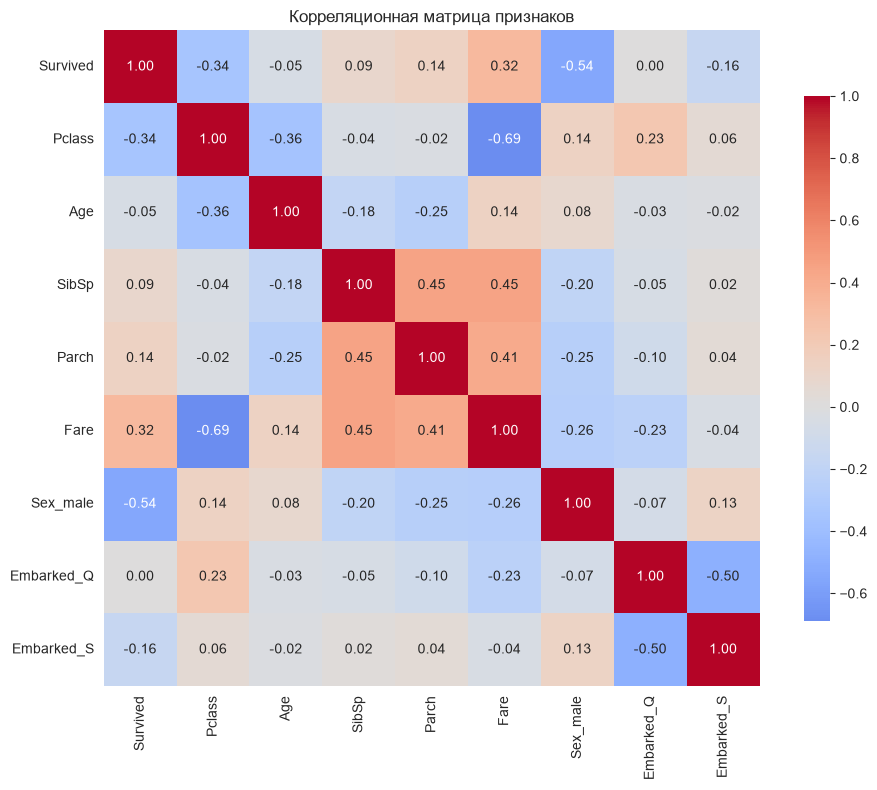

In [5]:
corr_df = df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].copy()
corr_df['Sex_male'] = (df['Sex'] == 'male').astype(int)
emb_dummies = pd.get_dummies(df['Embarked'], prefix='Embarked', drop_first=True, dtype=int)
corr_df = pd.concat([corr_df, emb_dummies], axis=1)

corr = corr_df.corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    cbar_kws={'shrink': 0.8}
)
plt.title('Корреляционная матрица признаков')
plt.tight_layout()
plt.show()

In [6]:
sex_surv = df.groupby('Sex')['Survived'].agg(['count', 'mean']).rename(
    columns={'count': 'n', 'mean': 'survival_rate'}
)
sex_surv['survival_rate'] = sex_surv['survival_rate'].round(3)
print('Survival by Sex:')
print(sex_surv.to_string())

pclass_surv = df.groupby('Pclass')['Survived'].agg(['count', 'mean']).rename(
    columns={'count': 'n', 'mean': 'survival_rate'}
)
pclass_surv['survival_rate'] = pclass_surv['survival_rate'].round(3)
print('\nSurvival by Pclass:')
print(pclass_surv.to_string())


Survival by Sex:
          n  survival_rate
Sex                       
female  314          0.742
male    577          0.189

Survival by Pclass:
          n  survival_rate
Pclass                    
1       216          0.630
2       184          0.473
3       491          0.242


Корреляционная матрица показывает, что Fare и Pclass заметно отрицательно коррелируют: чем выше класс, тем дороже билет. Для интерпретации feature importance это важно, потому что деревья могут отдавать предпочтение одному из них, и важность второго падает, хотя сам признак информативен, но его вклад уже объяснён коррелирующим признаком. По распределению целевой переменной видно расслоение выживаемости: доля выживших у женщин заметно выше, чем у мужчин, и падает с ростом номера класса (1 → 2 → 3). В кросс-таблице Sex × Pclass максимальная выживаемость у женщин 1–2 класса, минимальная - у мужчин 3 класса, то есть Sex и Pclass объясняют различия в выживаемости не по отдельности, а совместно.

Из обучения исключаются PassengerId, Name, Ticket и Cabin - это признаки, которые идентифицируют пассажира либо обладают высокой кардинальностью, что ведёт к утечке и запоминанию объектов. Pclass остаётся числовым порядковым признаком. Sex и Embarked - категориальные, кодируются one-hot (drop first). Age заполняется медианой, так как распределение возраста смещено, а медиана устойчивее к выбросам, Embarked - самым частым значением (т.к. пропущено всего две записи). Масштабирование выполняется только для SVM и KNN, где важно расстояние между объектами, для деревьев RF и GB масштаб не нужен. Оба препроцессора обучаются строго на X_train, transform применяется к train и test.

In [7]:
cat_cols = ['Sex', 'Embarked']
num_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
drop_cols = ['PassengerId', 'Name', 'Ticket', 'Cabin']

X = df.drop(columns=['Survived'] + drop_cols)
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train size:', X_train.shape, '| Test size:', X_test.shape)
print('Train target share:', y_train.value_counts(normalize=True).round(4).to_dict())
print('Test  target share:', y_test.value_counts(normalize=True).round(4).to_dict())

preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_cols),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(drop='first', sparse_output=False))
        ]), cat_cols)
    ]
)

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(drop='first', sparse_output=False))
        ]), cat_cols)
    ]
)

X_train_tree = preprocessor_tree.fit_transform(X_train)
X_test_tree = preprocessor_tree.transform(X_test)

X_train_scaled = preprocessor_scaled.fit_transform(X_train)
X_test_scaled = preprocessor_scaled.transform(X_test)

feature_names = preprocessor_tree.get_feature_names_out()

Train size: (712, 7) | Test size: (179, 7)
Train target share: {0: 0.6166, 1: 0.3834}
Test  target share: {0: 0.6145, 1: 0.3855}


Train и test сохраняют исходную долю выживших благодаря stratify, поэтому метрики на тесте сопоставимы с baseline. Матрицы без масштабирования (X_train_tree/X_test_tree) используются для Decision Tree, Random Forest и Gradient Boosting. Масштабированные версии (X_train_scaled/X_test_scaled) - для SVM и KNN; StandardScaler обучен на train и применён к test через transform, утечки нет. Имена признаков после one-hot сохранены в feature_names, чтобы на этапе feature importance корректно сопоставить веса моделей исходным признакам.

model: Baseline (most_frequent)
accuracy: 0.6145
precision: 0.0000
recall: 0.0000
f1: 0.0000


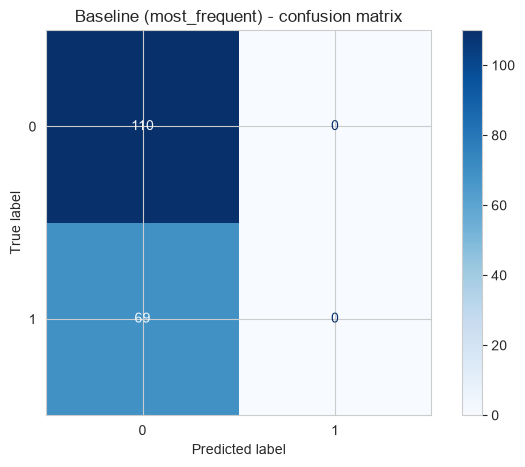

In [8]:
baseline = DummyClassifier(strategy='most_frequent', random_state=42)
baseline.fit(X_train_tree, y_train)
y_pred_base = baseline.predict(X_test_tree)

baseline_metrics = {
    'model': 'Baseline (most_frequent)',
    'accuracy': accuracy_score(y_test, y_pred_base),
    'precision': precision_score(y_test, y_pred_base, zero_division=0),
    'recall': recall_score(y_test, y_pred_base, zero_division=0),
    'f1': f1_score(y_test, y_pred_base, zero_division=0),
}

for k, v in baseline_metrics.items():
    print(f'{k}: {v:.4f}' if isinstance(v, float) else f'{k}: {v}')

cm_base = confusion_matrix(y_test, y_pred_base)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_base, display_labels=['0', '1'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Baseline (most_frequent) - confusion matrix')
plt.show()

results = []
results.append(baseline_metrics)

Baseline всегда предсказывает класс 0, потому что он самый частый в train. Отсюда все его метрики по классу 1 нулевые: Precision, Recall и F1 равны 0, а Accuracy при этом около 0.62, что совпадает с долей невыживших в датасете. В confusion matrix весь вес сосредоточен в одной ячейке (TN), FN равен числу реальных выживших в тесте - это и объясняет нулевой Recall.

Decision Tree
accuracy: 0.7765
precision: 0.8085
recall: 0.5507
f1: 0.6552

Decision Tree train vs test
train accuracy: 0.8315 | test accuracy: 0.7765
train F1:       0.7447 | test F1:       0.6552


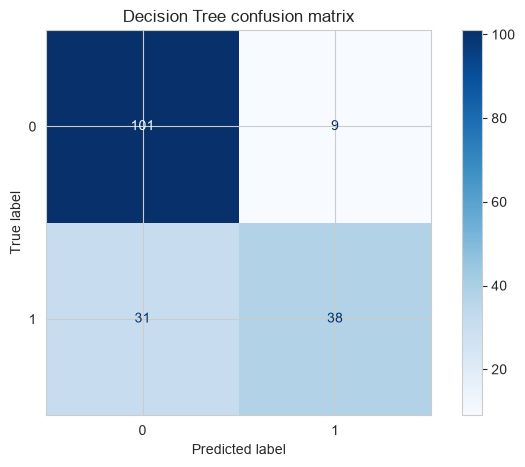

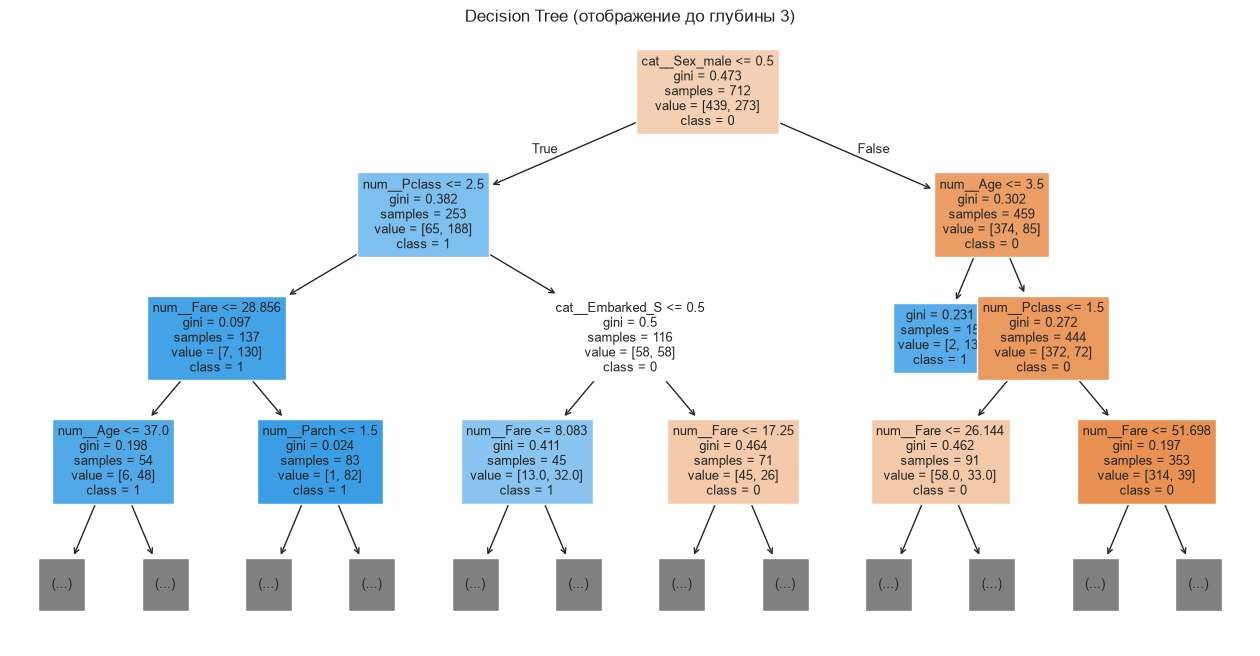

In [9]:
dt = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=10,
    random_state=42
)
dt.fit(X_train_tree, y_train)

y_pred_dt_train = dt.predict(X_train_tree)
y_pred_dt_test = dt.predict(X_test_tree)

dt_metrics = {
    'model': 'Decision Tree',
    'accuracy': accuracy_score(y_test, y_pred_dt_test),
    'precision': precision_score(y_test, y_pred_dt_test, zero_division=0),
    'recall': recall_score(y_test, y_pred_dt_test, zero_division=0),
    'f1': f1_score(y_test, y_pred_dt_test, zero_division=0),
    'train_accuracy': accuracy_score(y_train, y_pred_dt_train),
    'train_f1': f1_score(y_train, y_pred_dt_train, zero_division=0),
}

print('Decision Tree')
for k in ['accuracy', 'precision', 'recall', 'f1']:
    print(f'{k}: {dt_metrics[k]:.4f}')
print('\nDecision Tree train vs test')
print(f'train accuracy: {dt_metrics["train_accuracy"]:.4f} | test accuracy: {dt_metrics["accuracy"]:.4f}')
print(f'train F1:       {dt_metrics["train_f1"]:.4f} | test F1:       {dt_metrics["f1"]:.4f}')

cm_dt = confusion_matrix(y_test, y_pred_dt_test)
ConfusionMatrixDisplay(cm_dt, display_labels=['0', '1']).plot(cmap='Blues', values_format='d')
plt.title('Decision Tree confusion matrix')
plt.show()

plt.figure(figsize=(16, 8))
plot_tree(
    dt,
    filled=True,
    feature_names=list(feature_names),
    class_names=['0', '1'],
    max_depth=3,
    fontsize=9
)
plt.title('Decision Tree (отображение до глубины 3)')
plt.show()

results.append({k: dt_metrics[k] for k in ['model', 'accuracy', 'precision', 'recall', 'f1']})

Дерево решений обучено с регуляризацией: max_depth=4 и min_samples_leaf=10 ограничивают глубину и запрещают листьям быть слишком мелкими, что убирает вырожденные разбиения под отдельные объекты. На test Precision, Recall и F1 заметно выше нуля, accuracy также выросла по сравнению с baseline. Сравнение train и test показывает, что качество на train выше, чем на test - это признак частичного переобучения, которое типично для деревьев: они жадно подбирают разбиения и легко запоминают обучающую выборку. Регуляризация это переобучение сдерживает, но не устраняет полностью. На confusion matrix видно распределение FP и FN. Заметим, что количество FN предсказаний сопоставимо с TP, отчего метрика не прошла порог. В контексте Titanic FN принимаем как более критичную ошибку, потому что она означает пропуск реально выжившего пассажира, тогда как FP - избыточное предсказание выживания. Дерево даёт интерпретируемую структуру, и plot_tree до глубины 3 показывает, что разбиения идут по полу, возрасту и классу и стоимости тарифа - это согласуется с EDA.

Дополнительно проведем подбор гиперпараметров Decision Tree с помощью GridSearchCV (5-fold CV на train, метрика F1). В leaderboard эту модель не включается, т.к. для честности сравнения стоило бы проделать GridSearch для всех обучаемых моделей, чего нет в ТЗ лабораторной работы.

Лучшие параметры (по 5-fold CV на train): {'max_depth': 8, 'min_samples_leaf': 5}
Train F1: 0.8433
Test F1:  0.7087


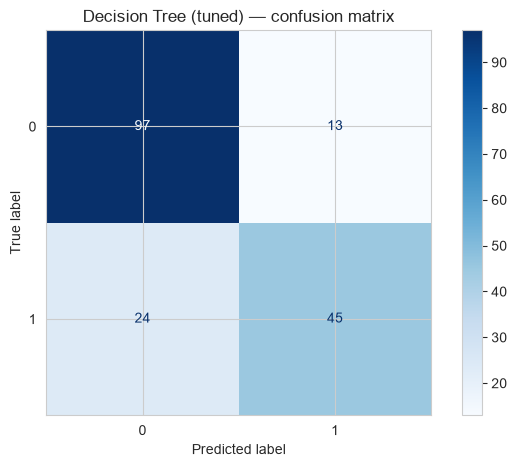

In [11]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [3, 4, 5, 6, 8, 10],
    'min_samples_leaf': [1, 2, 5, 10, 15, 20]
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_dt.fit(X_train_tree, y_train)
best_dt = grid_dt.best_estimator_

y_pred_best_dt_train = best_dt.predict(X_train_tree)
y_pred_best_dt_test = best_dt.predict(X_test_tree)

print('Лучшие параметры (по 5-fold CV на train):', grid_dt.best_params_)
print(f'Train F1: {f1_score(y_train, y_pred_best_dt_train, zero_division=0):.4f}')
print(f'Test F1:  {f1_score(y_test, y_pred_best_dt_test, zero_division=0):.4f}')

cm_best_dt = confusion_matrix(y_test, y_pred_best_dt_test)
ConfusionMatrixDisplay(cm_best_dt, display_labels=['0', '1']).plot(cmap='Blues', values_format='d')
plt.title('Decision Tree (tuned) — confusion matrix')
plt.show()

Лучшие параметры: max_depth=8 , min_samples_leaf=5. Модель превзошла порог 0.70. Разрыв train/test F1 составляет ~ 0,14.

In [169]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)
rf.fit(X_train_tree, y_train)

y_pred_rf = rf.predict(X_test_tree)

rf_metrics = {
    'model': 'Random Forest',
    'accuracy': accuracy_score(y_test, y_pred_rf),
    'precision': precision_score(y_test, y_pred_rf, zero_division=0),
    'recall': recall_score(y_test, y_pred_rf, zero_division=0),
    'f1': f1_score(y_test, y_pred_rf, zero_division=0),
}

print('Random Forest test metrics')
for k in ['accuracy', 'precision', 'recall', 'f1']:
    print(f'{k}: {rf_metrics[k]:.4f}')

y_pred_rf_train = rf.predict(X_train_tree)
rf_train_f1 = f1_score(y_train, y_pred_rf_train, zero_division=0)
rf_train_acc = accuracy_score(y_train, y_pred_rf_train)

print('Random Fores train vs test')
print(f'train accuracy: {rf_train_acc:.4f} | test accuracy: {rf_metrics["accuracy"]:.4f}')
print(f'train F1:       {rf_train_f1:.4f} | test F1:       {rf_metrics["f1"]:.4f}')


Random Forest test metrics
accuracy: 0.8212
precision: 0.7937
recall: 0.7246
f1: 0.7576
Random Fores train vs test
train accuracy: 0.9831 | test accuracy: 0.8212
train F1:       0.9778 | test F1:       0.7576


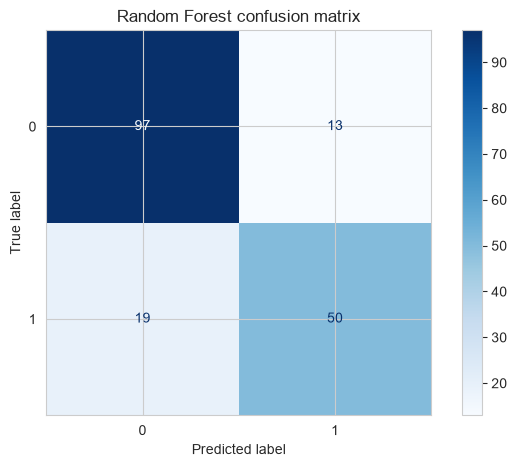


Random Forest feature importances (top-5):
num__Fare        0.2720
cat__Sex_male    0.2607
num__Age         0.2554
num__Pclass      0.0881
num__SibSp       0.0502


In [170]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
ConfusionMatrixDisplay(cm_rf, display_labels=['0', '1']).plot(cmap='Blues', values_format='d')
plt.title('Random Forest confusion matrix')
plt.show()

rf_importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
print('\nRandom Forest feature importances (top-5):')
print(rf_importances.head(5).round(4).to_string())

results.append({k: rf_metrics[k] for k in ['model', 'accuracy', 'precision', 'recall', 'f1']})

Random Forest - это ансамбль деревьев, каждое обучается на bootstrap-выборке и на случайном подмножестве признаков, а итоговое предсказание - голосование большинства. Из-за усреднения по многим деревьям дисперсия падает, и модель даёт заметно более высокий F1, чем одно дерево. По сравнению с Decision Tree на том же split, RF вытягивает recall: одно дерево много выживших помечало как 0, а ансамбль сглаживает такие ошибки и находит больше истинных выживших, что напрямую поднимает F1. Именно сокращение FN даёт основной прирост F1. Признаки Fare и Sex лидируют, за ними идут Age и Pclass, что согласуется с EDA (женщины и пассажиры более высокого класса выживали чаще).

In [171]:
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
gb.fit(X_train_tree, y_train)

y_pred_gb = gb.predict(X_test_tree)

gb_metrics = {
    'model': 'Gradient Boosting',
    'accuracy': accuracy_score(y_test, y_pred_gb),
    'precision': precision_score(y_test, y_pred_gb, zero_division=0),
    'recall': recall_score(y_test, y_pred_gb, zero_division=0),
    'f1': f1_score(y_test, y_pred_gb, zero_division=0),
}

print('Gradient Boosting test metrics')
for k in ['accuracy', 'precision', 'recall', 'f1']:
    print(f'{k}: {gb_metrics[k]:.4f}')

y_pred_gb_train = gb.predict(X_train_tree)
gb_train_f1 = f1_score(y_train, y_pred_gb_train, zero_division=0)
gb_train_acc = accuracy_score(y_train, y_pred_gb_train)

print('Gradient Boosting train vs test')
print(f'train accuracy: {gb_train_acc:.4f} | test accuracy: {gb_metrics["accuracy"]:.4f}')
print(f'train F1:       {gb_train_f1:.4f} | test F1:       {gb_metrics["f1"]:.4f}')

Gradient Boosting test metrics
accuracy: 0.8045
precision: 0.8400
recall: 0.6087
f1: 0.7059
Gradient Boosting train vs test
train accuracy: 0.8722 | test accuracy: 0.8045
train F1:       0.8162 | test F1:       0.7059


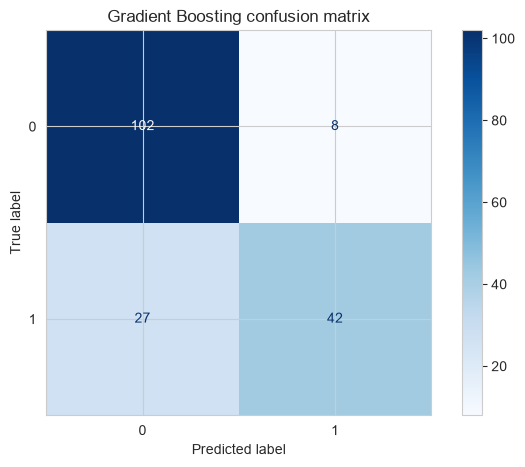


Gradient Boosting feature importances (top-5):
cat__Sex_male    0.5086
num__Pclass      0.1622
num__Fare        0.1509
num__Age         0.1291
num__SibSp       0.0260


In [172]:
cm_gb = confusion_matrix(y_test, y_pred_gb)
ConfusionMatrixDisplay(cm_gb, display_labels=['0', '1']).plot(cmap='Blues', values_format='d')
plt.title('Gradient Boosting confusion matrix')
plt.show()

gb_importances = pd.Series(gb.feature_importances_, index=feature_names).sort_values(ascending=False)
print('\nGradient Boosting feature importances (top-5):')
print(gb_importances.head(5).round(4).to_string())

results.append({k: gb_metrics[k] for k in ['model', 'accuracy', 'precision', 'recall', 'f1']})

Gradient Boosting строит деревья последовательно, каждое следующее компенсирует ошибки предыдущих, поэтому при заметно меньшем числе деревьев, качество не сильно хуже чем у RF. Параметры выбраны как умеренные: learning_rate=0.05 и max_depth=3 - это небольшие шаги и неглубокие базовые деревья, а также небольшая скорость обучения, что делает ансамбль более стабильным. Feature importances GB считаются по суммарному снижению неоднородности от разбиений на этом признаке за все деревья. В топе вновь Sex, Pclass, Fare, Age, как и было отмечено при EDA, но по сравнению с RF распределение важностей более равномерное.

In [173]:
svm_raw = SVC(random_state=42)
svm_raw.fit(X_train_tree, y_train)
y_pred_svm_raw = svm_raw.predict(X_test_tree)

svm_scaled = SVC(random_state=42)
svm_scaled.fit(X_train_scaled, y_train)
y_pred_svm_scaled = svm_scaled.predict(X_test_scaled)

def _metrics(y_true, y_pred, name):
    return {
        'model': name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
    }

svm_raw_metrics = _metrics(y_test, y_pred_svm_raw, 'SVM (без масштабирования)')
svm_scaled_metrics = _metrics(y_test, y_pred_svm_scaled, 'SVM (StandardScaler)')

print('SVM без масштабирования')
for k in ['accuracy', 'precision', 'recall', 'f1']:
    print(f'{k}: {svm_raw_metrics[k]:.4f}')

print('\nSVM со StandardScaler')
for k in ['accuracy', 'precision', 'recall', 'f1']:
    print(f'{k}: {svm_scaled_metrics[k]:.4f}')

SVM без масштабирования
accuracy: 0.6201
precision: 0.5161
recall: 0.2319
f1: 0.3200

SVM со StandardScaler
accuracy: 0.8324
precision: 0.8305
recall: 0.7101
f1: 0.7656


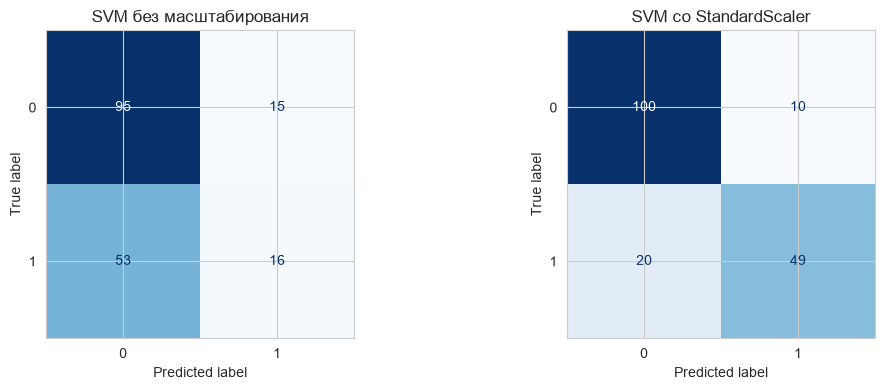

In [174]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_svm_raw), display_labels=['0', '1']).plot(
    ax=axes[0], cmap='Blues', values_format='d', colorbar=False
)
axes[0].set_title('SVM без масштабирования')
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_svm_scaled), display_labels=['0', '1']).plot(
    ax=axes[1], cmap='Blues', values_format='d', colorbar=False
)
axes[1].set_title('SVM со StandardScaler')
plt.tight_layout()
plt.show()

results.append({k: svm_scaled_metrics[k] for k in ['model', 'accuracy', 'precision', 'recall', 'f1']})

SVM обучен в двух вариантах, чтобы показать роль масштабирования. SVC с RBF-ядром принимает решение по расстоянию между объектами в пространстве признаков: ядро фактически считает скалярное произведение и квадрат расстояния между точками, и если признаки имеют разные масштабы, расстояние определяется самым крупным по разбросу признаком, а остальные почти не влияют. В наших данных это критично: Fare измеряется десятками и сотнями (есть билеты по 512), а SibSp и Parch - это 0, 1, 2, Pclass - 1–3, one-hot столбцы - 0/1. Без масштабирования расстояние между пассажирами почти полностью задаётся Fare, поэтому SVM фактически строит границу по одному признаку и игнорирует остальные - отсюда низкие precision, recall и F1 без масштабирования. StandardScaler приводит числовые признаки к сопоставимому масштабу, после чего все признаки вносят вклад в расстояние, и SVM находит содержательную границу, а F1 и recall заметно растут. FP и FN по-прежнему означают ложную тревогу и пропущенного выжившего. На немасштабированных данных SVM часто смещается в сторону одного класса, и в confusion matrix это видно как перекос между FP и FN. Вывод: для SVM масштабирование - обязательное условие корректной работы алгоритма, потому что он основан на расстоянии.

In [184]:
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train_tree, y_train)
y_pred_knn_raw = knn_raw.predict(X_test_tree)

knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train)
y_pred_knn_scaled = knn_scaled.predict(X_test_scaled)

knn_raw_metrics = _metrics(y_test, y_pred_knn_raw, 'KNN (без масштабирования)')
knn_scaled_metrics = _metrics(y_test, y_pred_knn_scaled, 'KNN (StandardScaler)')

print('KNN - без масштабирования')
for k in ['accuracy', 'precision', 'recall', 'f1']:
    print(f'{k}: {knn_raw_metrics[k]:.4f}')

print('\nKNN - со StandardScaler')
for k in ['accuracy', 'precision', 'recall', 'f1']:
    print(f'{k}: {knn_scaled_metrics[k]:.4f}')

KNN - без масштабирования
accuracy: 0.6816
precision: 0.5968
recall: 0.5362
f1: 0.5649

KNN - со StandardScaler
accuracy: 0.8156
precision: 0.8103
recall: 0.6812
f1: 0.7402


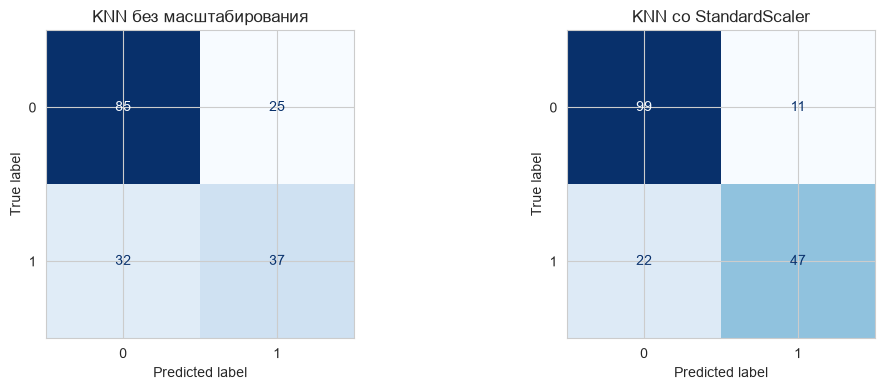

In [176]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_knn_raw), display_labels=['0', '1']).plot(
    ax=axes[0], cmap='Blues', values_format='d', colorbar=False
)
axes[0].set_title('KNN без масштабирования')
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_knn_scaled), display_labels=['0', '1']).plot(
    ax=axes[1], cmap='Blues', values_format='d', colorbar=False
)
axes[1].set_title('KNN со StandardScaler')
plt.tight_layout()
plt.show()

results.append({k: knn_scaled_metrics[k] for k in ['model', 'accuracy', 'precision', 'recall', 'f1']})

KNN классифицирует объект по пяти ближайшим соседям в пространстве признаков, и понятие "ближайший" целиком определяется расстоянием. Здесь расстояние - это сумма квадратов разностей по всем признакам, поэтому признак с большим разбросом вносит в расстояние больший вклад, чем признак с малым. В наших данных, как было упомянуто, Fare имеет огромный разброс в сравнении с SibSp, Parch, Pclass и one-hot столбцами. В результате KNN без масштабирования ищет соседей по цене билета и игнорирует остальные признаки, что даёт низкие precision, recall и F1 и перекос в confusion matrix. StandardScaler приводит каждый числовой признак к среднему 0 и стандартному отклонению 1, после чего все признаки вносят сопоставимый вклад в расстояние, соседи находятся по совокупности признаков, и качество заметно растёт: F1 и recall увеличиваются, FP и FN становятся более сбалансированными. Как и для SVM, scaler обучен только на train и применён к test через transform, иначе была бы утечка. Вывод: для KNN масштабирование не опция, а обязательное условие корректной работы, потому что алгоритм целиком построен на расстоянии между объектами.

In [177]:
leaderboard = pd.DataFrame(results).copy()
leaderboard['F1 > 0.70'] = leaderboard['f1'] > 0.70
leaderboard = leaderboard.sort_values('f1', ascending=False).reset_index(drop=True)
leaderboard = leaderboard[['model', 'accuracy', 'precision', 'recall', 'f1', 'F1 > 0.70']]

print('Leaderboard (тест, единый split):')
print(leaderboard.round(4).to_string(index=False))

Leaderboard (тест, единый split):
                   model  accuracy  precision  recall     f1  F1 > 0.70
    SVM (StandardScaler)    0.8324     0.8305  0.7101 0.7656       True
           Random Forest    0.8212     0.7937  0.7246 0.7576       True
    KNN (StandardScaler)    0.8156     0.8103  0.6812 0.7402       True
       Gradient Boosting    0.8045     0.8400  0.6087 0.7059       True
           Decision Tree    0.7765     0.8085  0.5507 0.6552      False
Baseline (most_frequent)    0.6145     0.0000  0.0000 0.0000      False


Порог F1 > 0.70 прошли четыре модели: SVM со StandardScaler (F1 0.7656), Random Forest (0.7576), KNN со StandardScaler (0.7402) и Gradient Boosting (0.7059). Decision Tree порог не прошёл (F1 0.6552) и остался ниже, чем у всех остальных содержательных моделей.

Различия между моделями объясняются не "силой алгоритма", а тем, как каждая модель торгует precision и recall по классу 1. Decision Tree самый консервативный: precision 0.8085 при recall 0.5507 - когда дерево предсказывает выживание, оно чаще право, но очень много реальных выживших помечает как 0, то есть даёт много FN, и именно низкий recall тянет F1 вниз. Gradient Boosting идёт в ту же сторону, но менее выраженно: у него самый высокий precision в таблице (0.8400) и recall 0.6087, поэтому F1 0.7059 - он аккуратен, но пропускает выживших. Random Forest, наоборот, самый агрессивный по recall (0.7246) при precision 0.7937: он находит больше истинных выживших, и именно сокращение FN даёт ему F1 0.7576. SVM со StandardScaler занимает лучшее место в таблице (F1 0.7656) за счёт более сбалансированного сочетания precision 0.8305 и recall 0.7101: он почти так же аккуратен, как GB, но при этом существенно лучше находит выживших. KNN со StandardScaler - промежуточный вариант (precision 0.8103, recall 0.6812, F1 0.7402). Поскольку пропуск реально выжившего (FN) критичнее ложной тревоги (FP), модели с более высоким recall при сопоставимом precision и оказываются выше по F1, и это объясняет порядок верхней части таблицы.


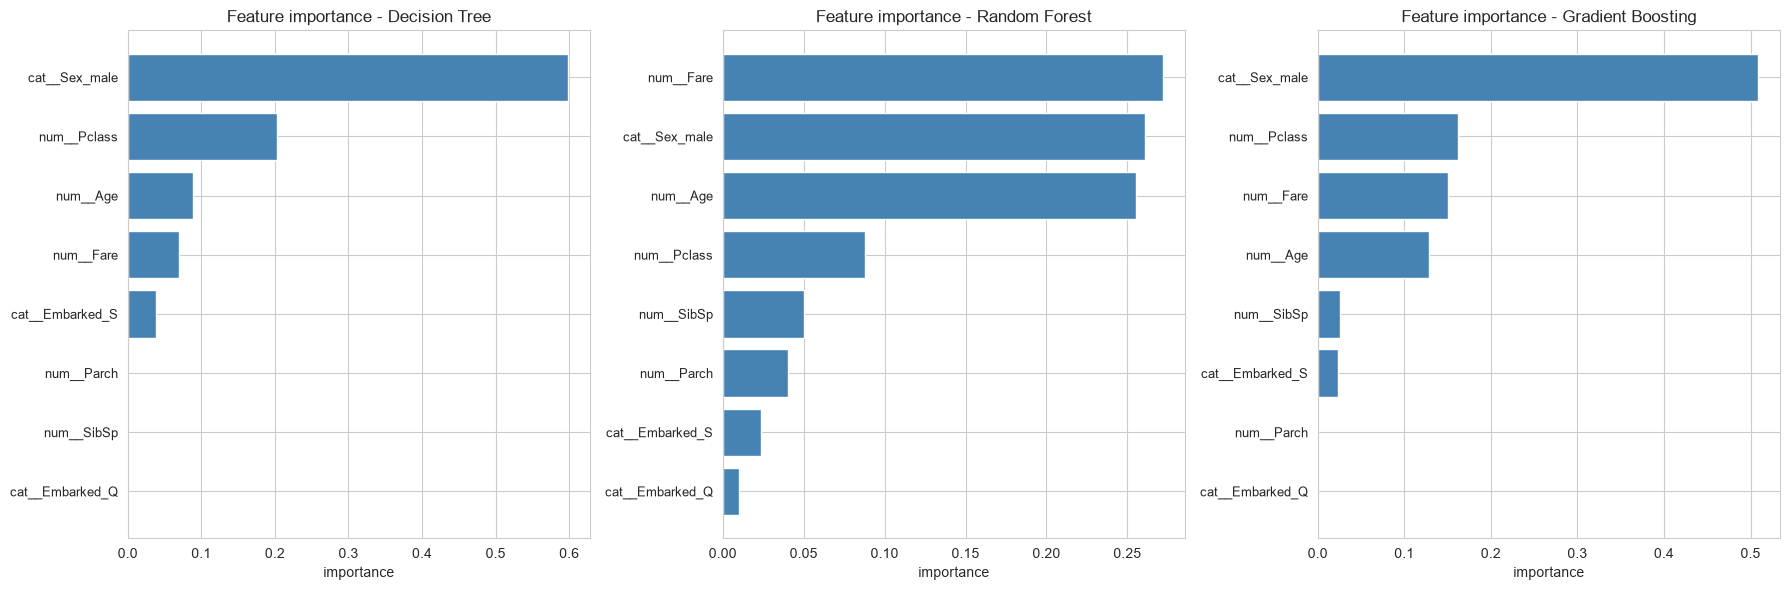


Decision Tree - top-5:
cat__Sex_male      0.5983
num__Pclass        0.2034
num__Age           0.0888
num__Fare          0.0700
cat__Embarked_S    0.0386

Random Forest - top-5:
num__Fare        0.2720
cat__Sex_male    0.2607
num__Age         0.2554
num__Pclass      0.0881
num__SibSp       0.0502

Gradient Boosting - top-5:
cat__Sex_male    0.5086
num__Pclass      0.1622
num__Fare        0.1509
num__Age         0.1291
num__SibSp       0.0260


In [180]:
dt_importances = pd.Series(dt.feature_importances_, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, imp, title in zip(
    axes,
    [dt_importances, rf_importances, gb_importances],
    ['Decision Tree', 'Random Forest', 'Gradient Boosting']
):
    top = imp.head(10).iloc[::-1]
    ax.barh(top.index, top.values, color='steelblue')
    ax.set_title(f'Feature importance - {title}')
    ax.set_xlabel('importance')
    ax.tick_params(axis='y', labelsize=9)

plt.tight_layout()
plt.show()

for name, imp in [('Decision Tree', dt_importances),
                  ('Random Forest', rf_importances),
                  ('Gradient Boosting', gb_importances)]:
    print(f'\n{name} - top-5:')
    print(imp.head(5).round(4).to_string())

Топ-4 признака у всех трёх моделей совпадают: Sex_male, Fare, Age, Pclass. Это подтверждает EDA, где Sex и Pclass объясняли расслоение выживаемости, а корреляционная матрица показала сильную связь Fare и Pclass. SibSp, Parch и Embarked идут далеко позади у всех моделей.

Различия в распределении - следствие устройства алгоритмов. DT при max_depth=4 и min_samples_leaf=10 имеет мало разбиений, поэтому концентрирует важность на двух признаках (Sex_male 0.60, Pclass 0.20). RF распределяет вклад между Fare, Sex_male и Age почти поровну (0.27 / 0.26 / 0.26), а Pclass получает всего 0.09: бэггинг и случайные подмножества признаков "размазывают" вклад коррелирующей пары Fare и Pclass. GB концентрирует больше половины важности на Sex_male (0.51), а Fare и Pclass делят скромные доли (0.15 и 0.16): жадный выбор лучшего разбиения на каждом шаге снова и снова ставит на самый сильный сигнал. Порядок Fare vs Pclass меняется между RF (Fare выше) и GB (Pclass выше) - прямое подтверждение корреляции этих признаков из EDA: кто выше в топе, зависит от механизма модели, а не от того, что второй признак неважен.

Важность не равно причинность. Feature importance измеряет вклад признака в снижение неоднородности, а не причинный эффект на выживание. Fare не "спасал" пассажира - он посредник для класса, расположения каюты и социального положения, аналогично Sex_male - посредник для правила "женщины первыми". При корреляции признаков важность может перемещаться между ними без изменения качества модели, как у пары Fare и Pclass.

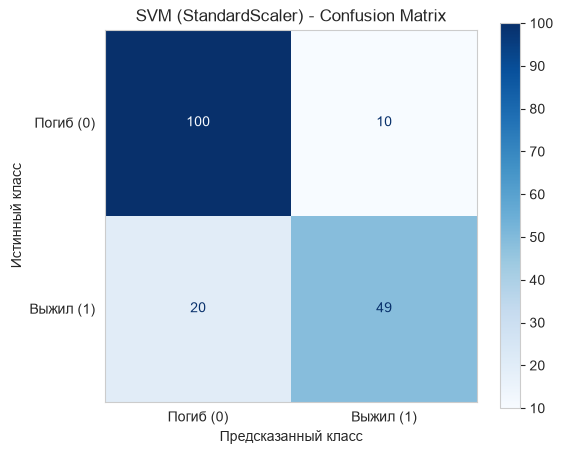

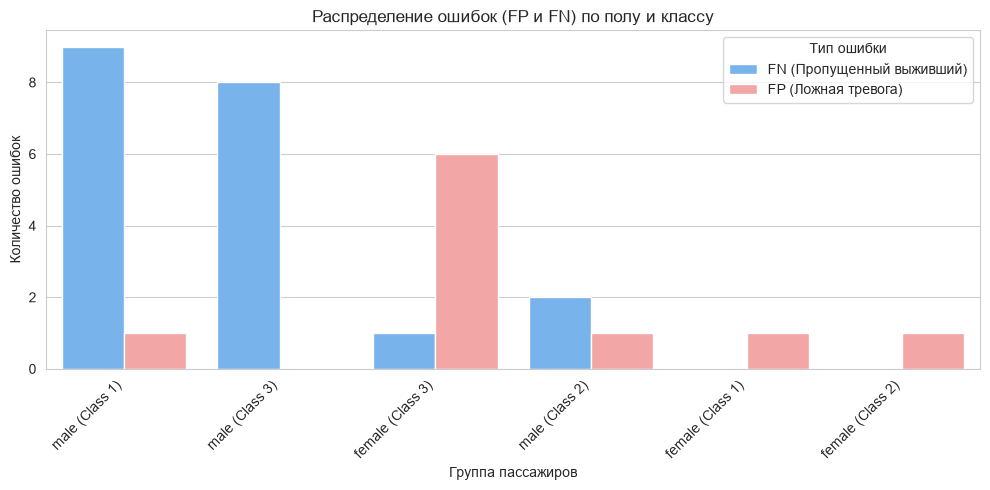

Примеры ошибок (FN - пропущенные выжившие):
                             Name    Sex  Age  Pclass   Fare
Leeni, Mr. Fahim ("Philip Zenni")   male 22.0       3  7.225
 Abbott, Mrs. Stanton (Rosa Hunt) female 35.0       3 20.250

Примеры ошибок (FP - ложные тревоги):
                          Name    Sex  Age  Pclass   Fare
Fortune, Mr. Charles Alexander   male 19.0       1 263.00
  Allison, Miss. Helen Loraine female  2.0       1 151.55


In [183]:
fig, ax = plt.subplots(figsize=(6, 5))
cm_svm = confusion_matrix(y_test, y_pred_svm_scaled)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=['Погиб (0)', 'Выжил (1)'])
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('SVM (StandardScaler) - Confusion Matrix')
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
plt.grid(False)
plt.show()

err_df = X_test.copy()
err_df['Name'] = df.loc[X_test.index, 'Name']
err_df['y_true'] = y_test
err_df['y_pred'] = y_pred_svm_scaled

errors = err_df[err_df['y_true'] != err_df['y_pred']].copy()
errors['Error Type'] = errors.apply(lambda row: 'FP (Ложная тревога)' if row['y_pred'] == 1 else 'FN (Пропущенный выживший)', axis=1)
errors['Group'] = errors['Sex'] + ' (Class ' + errors['Pclass'].astype(str) + ')'

plt.figure(figsize=(10, 5))
sns.countplot(
    data=errors, 
    x='Group', 
    hue='Error Type', 
    palette={'FP (Ложная тревога)': '#ff9999', 'FN (Пропущенный выживший)': '#66b3ff'},
    order=errors['Group'].value_counts().index
)
plt.title('Распределение ошибок (FP и FN) по полу и классу')
plt.xlabel('Группа пассажиров')
plt.ylabel('Количество ошибок')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Тип ошибки')
plt.tight_layout()
plt.show()

print('Примеры ошибок (FN - пропущенные выжившие):')
print(errors[errors['Error Type'].str.startswith('FN')][['Name', 'Sex', 'Age', 'Pclass', 'Fare']].head(2).to_string(index=False))

print('\nПримеры ошибок (FP - ложные тревоги):')
print(errors[errors['Error Type'].str.startswith('FP')][['Name', 'Sex', 'Age', 'Pclass', 'Fare']].head(2).to_string(index=False))

Модель SVM допустила 30 ошибок: 20 FN (пропущенный выживший) и 10 FP (ложная тревога). Преобладание FN критично для Titanic, так как пропуск спасшегося хуже ложного ожидания.

По графику основная масса ошибок: у мужчин 1 и 3 класса преобладают FN (9 и 8 случаев) — модель консервативно предсказывает им гибель. У женщин 3 класса доминируют FP (6 случаев) — возможно, из-за нетипичных для класса признаков (высокий Fare) модель ожидала выживания. Примеры: Mr. Leeni (мужчина, 3 класс) выжил, но по профилю неотличим от погибших (FN). Mr. Fortune (мужчина, 1 класс, Fare=263) и Miss Allison (девочка, 2 года, 1 класс) погибли, хотя модель предсказала спасение из-за статуса и возраста (FP).

Проверка утечки: ID, Name, Ticket и Cabin исключены из обучения. Имена даны только для ручного разбора, модель опирается на обобщающие признаки (Sex, Fare, Pclass, Age), качество не получено за счёт запоминания.